# Semi-supervised forest training and two example predictions

This notebook delegates training to `train_vision_semi.py` instead of duplicating its training loop. That keeps the model, losses, schedules, checkpoint selection, and logging exactly the same as the script. After training, it loads `checkpoints/best.pt` and plots occupancy predictions for two forest images.

Run the notebook from the repository root, where `train_vision_semi.py`, `model.py`, `augmentations.py`, and the project modules are available. Edit the paths and training arguments in the next cell to match your run.

In [1]:
from pathlib import Path
import sys
import subprocess

# Run this notebook from the pose_from_cylinders repository root.
REPO_DIR = Path.cwd()
TRAIN_SCRIPT = REPO_DIR / "train_vision_semi.py"

# Match the short experiment configuration. Other values are the script defaults.
TRAIN_ARGS = {
    "--data-dir": ".",
    "--forest-dir": "forest_torpa",
    "--epochs": 10,
    "--batch-size": 16,
    "--val-interval": 10,
    "--num-workers": 8,
    "--img-size": 128,
    "--consistency-warmup-epochs": 2,
    "--consistency-ramp-epochs": 8,
    "--lambda-consistency": 1.0,
    "--lambda-occ-prior": 0.5,
    "--occ-prior-final-factor": 0.1,
    "--lambda-entropy": 0.05,
    "--topk-fraction": 0.072,
    "--lambda-topk-feedback": 0.05,
    "--output-dir": "runs/vision_semi_notebook",
}

# Optional: set this to an occupancy-pretrained checkpoint to continue in geometry
# stage. If set, the script requires --stage geometry.
INIT_CHECKPOINT = "runs/vision_geometry_good/checkpoints/best_vision.pt" 
if INIT_CHECKPOINT is not None:
    TRAIN_ARGS["--stage"] = "geometry"
    TRAIN_ARGS["--init-checkpoint"] = str(INIT_CHECKPOINT)

assert TRAIN_SCRIPT.exists(), f"Could not find {TRAIN_SCRIPT}. Set REPO_DIR to the repository root."
print("Repository:", REPO_DIR)
print("Training script:", TRAIN_SCRIPT)
print("Output:", REPO_DIR / TRAIN_ARGS["--output-dir"])

Repository: /home/johanna/Doktorand/pose_from_cylinders
Training script: /home/johanna/Doktorand/pose_from_cylinders/train_vision_semi.py
Output: /home/johanna/Doktorand/pose_from_cylinders/runs/vision_semi_notebook


## Train

The next cell runs the script with the arguments above. It can take as long as a normal script run. The selected checkpoint will be saved under the output directory's `checkpoints/best.pt`.

In [2]:
cmd = [sys.executable, str(TRAIN_SCRIPT)]
for name, value in TRAIN_ARGS.items():
    cmd.extend([name, str(value)])

print("Running:", " ".join(cmd), flush=True)
subprocess.run(cmd, cwd=REPO_DIR, check=True)

Running: /home/johanna/Doktorand/pose_from_cylinders/venv/bin/python /home/johanna/Doktorand/pose_from_cylinders/train_vision_semi.py --data-dir . --forest-dir forest_torpa --epochs 10 --batch-size 16 --val-interval 10 --num-workers 8 --img-size 128 --consistency-warmup-epochs 2 --consistency-ramp-epochs 8 --lambda-consistency 1.0 --lambda-occ-prior 0.5 --occ-prior-final-factor 0.1 --lambda-entropy 0.05 --topk-fraction 0.072 --lambda-topk-feedback 0.05 --output-dir runs/vision_semi_notebook --stage geometry --init-checkpoint runs/vision_geometry_good/checkpoints/best_vision.pt
Device: cuda | supervised=482 | validation=484 | forest=456
Loaded checkpoint runs/vision_geometry_good/checkpoints/best_vision.pt epoch 200
Epoch 1: total=3.8340 supervised=2.6889 cons=1.1977 (w=0.000) (occ=0.0060, geom=1.1916) occ_prior=0.2634*0.500 entropy=0.2546*0.0000 topk=1.2523*0.0000 topk_mutual=3.59/10 topk_overlap=0.359 gt_occ=0.073 forest_occ_mean=0.088 forest_occ>0.3=0.029 geom_active=0.050 | val_tota

CompletedProcess(args=['/home/johanna/Doktorand/pose_from_cylinders/venv/bin/python', '/home/johanna/Doktorand/pose_from_cylinders/train_vision_semi.py', '--data-dir', '.', '--forest-dir', 'forest_torpa', '--epochs', '10', '--batch-size', '16', '--val-interval', '10', '--num-workers', '8', '--img-size', '128', '--consistency-warmup-epochs', '2', '--consistency-ramp-epochs', '8', '--lambda-consistency', '1.0', '--lambda-occ-prior', '0.5', '--occ-prior-final-factor', '0.1', '--lambda-entropy', '0.05', '--topk-fraction', '0.072', '--lambda-topk-feedback', '0.05', '--output-dir', 'runs/vision_semi_notebook', '--stage', 'geometry', '--init-checkpoint', 'runs/vision_geometry_good/checkpoints/best_vision.pt'], returncode=0)

## Plot two forest examples

For each original image, the notebook runs the same pair model with that image supplied to both inputs, matching the two-view training setup. The right-hand plot shows occupancy probability by angular bin; the dashed line is the forest consistency threshold from the script arguments.

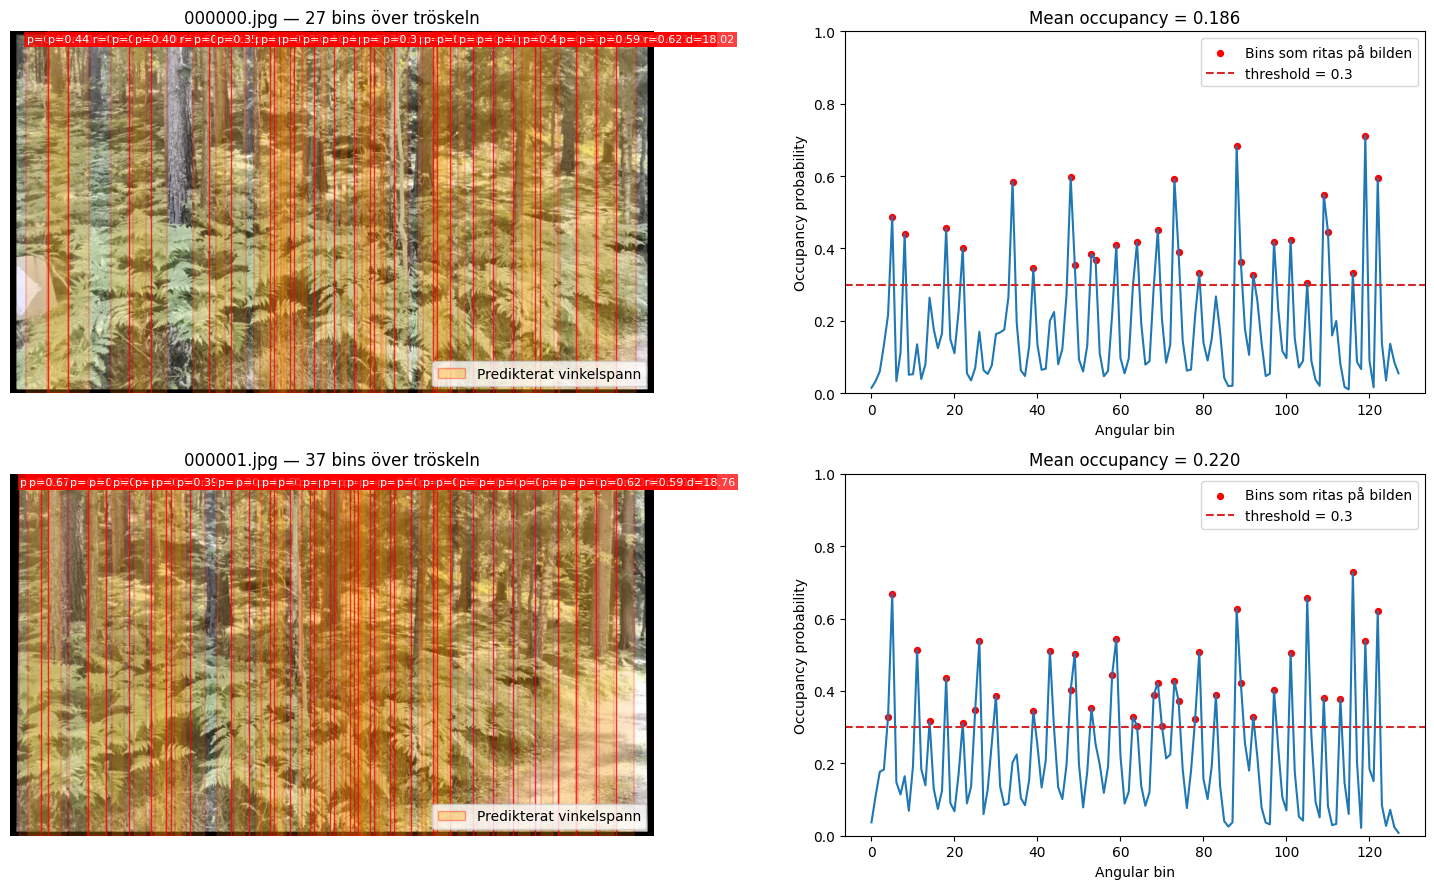

In [3]:
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image

from augmentations import build_eval_transform
from model import PairImageCylinderModel

output_dir = REPO_DIR / TRAIN_ARGS["--output-dir"]
checkpoint_path = output_dir / "checkpoints" / "latest.pt"
forest_dir = Path(TRAIN_ARGS["--forest-dir"])
if not forest_dir.is_absolute():
    forest_dir = REPO_DIR / forest_dir

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
saved_args = checkpoint["args"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PairImageCylinderModel(
    img_size=saved_args["img_size"],
    patch_size=tuple(saved_args["patch_size"]),
    in_chans=3,
    embed_dim=saved_args["embed_dim"],
    depth=saved_args["depth"],
    num_heads=saved_args["num_heads"],
    num_bins=saved_args["num_bins"],
    dropout=saved_args["dropout"],
).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

with open(forest_dir / "relative_poses.json", "r", encoding="utf-8") as f:
    pairs = json.load(f)

# Select two distinct images in a deterministic order.
image_names = []
seen = set()
for pair in pairs:
    for key in ("from_image", "to_image"):
        name = pair[key]
        if name not in seen:
            image_names.append(name)
            seen.add(name)
        if len(image_names) == 2:
            break
    if len(image_names) == 2:
        break

if len(image_names) < 2:
    raise RuntimeError("Forest dataset needs at least two distinct images.")

transform = build_eval_transform(saved_args["img_size"])
threshold = float(saved_args.get("forest_occ", 0.3))
fov_degrees = 90.0  # FOV used by the vision losses

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    gridspec_kw={"width_ratios": [1.3, 1.0]},
)

for row, name in enumerate(image_names):
    image_path = forest_dir / "images" / name
    with Image.open(image_path) as im:
        image = im.convert("RGB")

    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        outputs = model(
            image_tensor,
            image_tensor,
            return_corr=False,
            compute_pose=False,
        )
        prediction = outputs[0][0].float().cpu().numpy()

    occupancy = prediction[:, 0]
    radius = prediction[:, 1]
    depth = prediction[:, 2]
    width_degrees = prediction[:, 3]
    detected_bins = np.flatnonzero(occupancy >= threshold)

    # Project each detected bin's predicted angular width onto the image.
    # These are horizontal spans: the model does not predict vertical position
    # or cylinder height.
    image_width, image_height = image.size
    focal_px = image_width / (2.0 * np.tan(np.deg2rad(fov_degrees / 2.0)))
    center_px = image_width / 2.0
    bin_angles = np.linspace(
        -fov_degrees / 2.0,
        fov_degrees / 2.0,
        len(occupancy),
    )

    axes[row, 0].imshow(image)

    for bin_idx in detected_bins:
        center_angle = bin_angles[bin_idx]
        half_width = max(float(width_degrees[bin_idx]), 0.0) / 2.0

        left_angle = np.clip(
            center_angle - half_width,
            -fov_degrees / 2.0,
            fov_degrees / 2.0,
        )
        right_angle = np.clip(
            center_angle + half_width,
            -fov_degrees / 2.0,
            fov_degrees / 2.0,
        )

        left_px = center_px + focal_px * np.tan(np.deg2rad(left_angle))
        right_px = center_px + focal_px * np.tan(np.deg2rad(right_angle))
        left_px = np.clip(left_px, 0, image_width)
        right_px = np.clip(right_px, 0, image_width)

        axes[row, 0].add_patch(Rectangle(
            (left_px, 0),
            max(right_px - left_px, 1),
            image_height,
            facecolor="orange",
            edgecolor="red",
            linewidth=1.5,
            alpha=0.18,
        ))

        center_px_bin = center_px + focal_px * np.tan(np.deg2rad(center_angle))
        axes[row, 0].axvline(
            center_px_bin,
            color="red",
            linewidth=1,
            alpha=0.8,
        )

        label_x = np.clip(left_px + 2, 2, max(image_width - 50, 2))
        axes[row, 0].text(
            label_x,
            5,
            f"p={occupancy[bin_idx]:.2f} r={radius[bin_idx]:.2f} d={depth[bin_idx]:.2f}",
            color="white",
            fontsize=8,
            va="top",
            bbox={
                "facecolor": "red",
                "alpha": 0.75,
                "edgecolor": "none",
                "pad": 2,
            },
        )

    axes[row, 0].set_title(f"{name} — {len(detected_bins)} bins över tröskeln")
    axes[row, 0].axis("off")

    if len(detected_bins):
        axes[row, 0].legend(
            handles=[Patch(
                facecolor="orange",
                edgecolor="red",
                alpha=0.35,
                label="Predikterat vinkelspann",
            )],
            loc="lower right",
        )

    bins = np.arange(len(occupancy))
    axes[row, 1].plot(bins, occupancy, linewidth=1.5)
    axes[row, 1].scatter(
        detected_bins,
        occupancy[detected_bins],
        color="red",
        s=18,
        label="Bins som ritas på bilden",
    )
    axes[row, 1].axhline(
        threshold,
        color="tab:red",
        linestyle="--",
        label=f"threshold = {threshold:g}",
    )
    axes[row, 1].set_ylim(0, 1)
    axes[row, 1].set_xlabel("Angular bin")
    axes[row, 1].set_ylabel("Occupancy probability")
    axes[row, 1].set_title(f"Mean occupancy = {occupancy.mean():.3f}")
    axes[row, 1].legend()

plt.tight_layout()
plt.show()

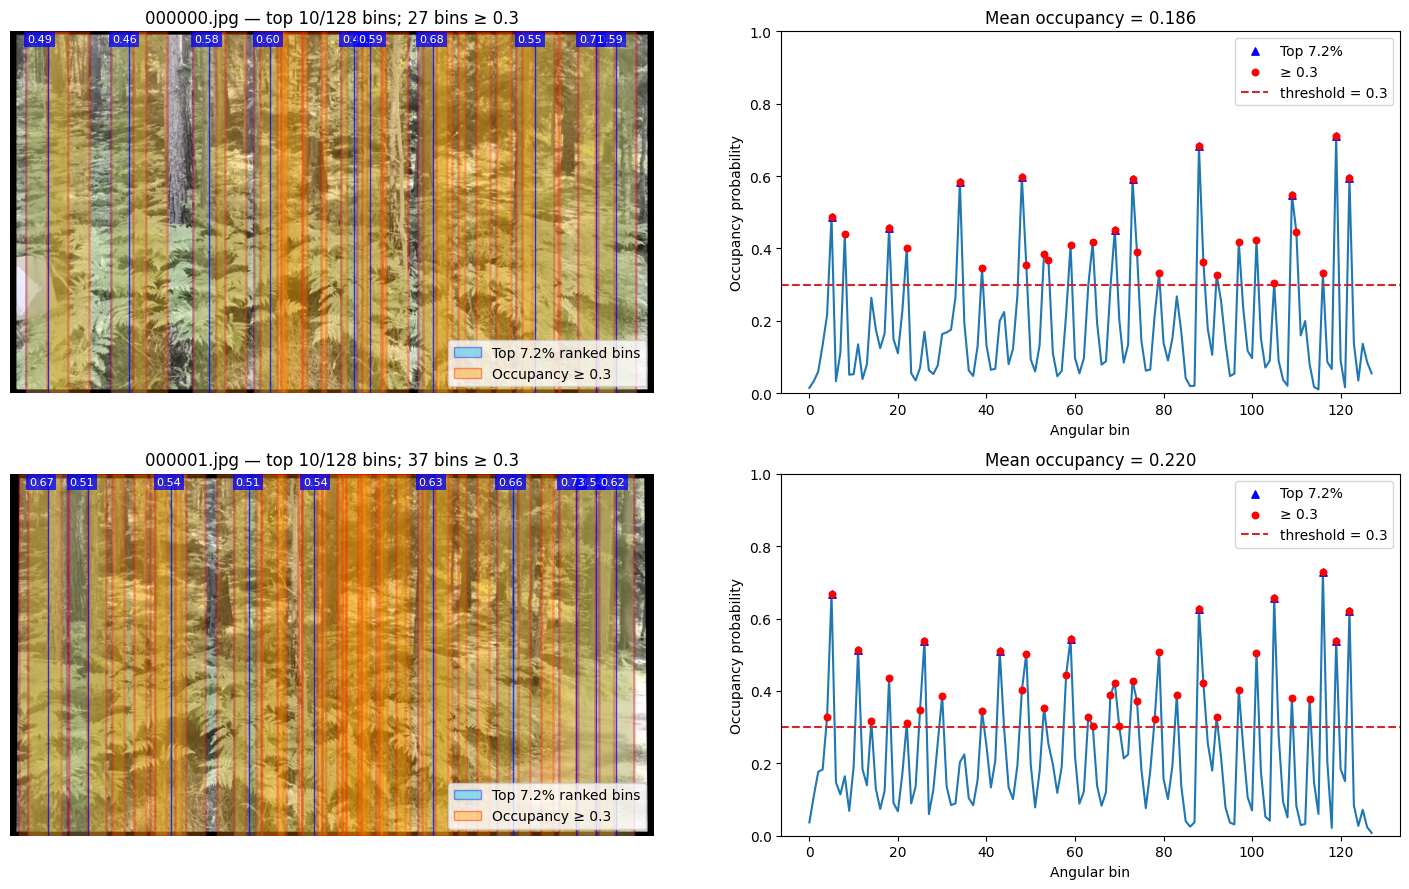

In [4]:
import json
import math
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image

from augmentations import build_eval_transform
from model import PairImageCylinderModel

output_dir = REPO_DIR / TRAIN_ARGS["--output-dir"]
checkpoint_path = output_dir / "checkpoints" / "latest.pt"
forest_dir = Path(TRAIN_ARGS["--forest-dir"])
if not forest_dir.is_absolute():
    forest_dir = REPO_DIR / forest_dir

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
saved_args = checkpoint["args"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PairImageCylinderModel(
    img_size=saved_args["img_size"],
    patch_size=tuple(saved_args["patch_size"]),
    in_chans=3,
    embed_dim=saved_args["embed_dim"],
    depth=saved_args["depth"],
    num_heads=saved_args["num_heads"],
    num_bins=saved_args["num_bins"],
    dropout=saved_args["dropout"],
).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

with open(forest_dir / "relative_poses.json", "r", encoding="utf-8") as f:
    pairs = json.load(f)

# Select two distinct images in a deterministic order.
image_names = []
seen = set()
for pair in pairs:
    for key in ("from_image", "to_image"):
        name = pair[key]
        if name not in seen:
            image_names.append(name)
            seen.add(name)
        if len(image_names) == 2:
            break
    if len(image_names) == 2:
        break

if len(image_names) < 2:
    raise RuntimeError("Forest dataset needs at least two distinct images.")

transform = build_eval_transform(saved_args["img_size"])
threshold = float(saved_args.get("forest_occ", 0.3))
top_fraction = 0.072
fov_degrees = 90.0

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    gridspec_kw={"width_ratios": [1.3, 1.0]},
)

for row, name in enumerate(image_names):
    image_path = forest_dir / "images" / name
    with Image.open(image_path) as im:
        image = im.convert("RGB")

    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        outputs = model(
            image_tensor,
            image_tensor,
            return_corr=False,
            compute_pose=False,
        )
        prediction = outputs[0][0].float().cpu().numpy()

    occupancy = prediction[:, 0]
    radius = prediction[:, 1]
    depth = prediction[:, 2]
    width_degrees = prediction[:, 3]

    num_bins = len(occupancy)
    top_k = max(1, math.ceil(top_fraction * num_bins))
    top_bins = np.argsort(occupancy)[-top_k:]
    threshold_bins = np.flatnonzero(occupancy >= threshold)

    # Project predicted angular spans into image pixels. These are horizontal
    # spans only; the model does not predict vertical position or cylinder height.
    image_width, image_height = image.size
    focal_px = image_width / (2.0 * np.tan(np.deg2rad(fov_degrees / 2.0)))
    center_px = image_width / 2.0
    bin_angles = np.linspace(-fov_degrees / 2.0, fov_degrees / 2.0, num_bins)

    axes[row, 0].imshow(image)

    # Draw the top 7.2% ranked bins in blue.
    for bin_idx in top_bins:
        center_angle = bin_angles[bin_idx]
        half_width = max(float(width_degrees[bin_idx]), 0.0) / 2.0

        left_angle = np.clip(
            center_angle - half_width,
            -fov_degrees / 2.0,
            fov_degrees / 2.0,
        )
        right_angle = np.clip(
            center_angle + half_width,
            -fov_degrees / 2.0,
            fov_degrees / 2.0,
        )

        left_px = center_px + focal_px * np.tan(np.deg2rad(left_angle))
        right_px = center_px + focal_px * np.tan(np.deg2rad(right_angle))
        left_px = np.clip(left_px, 0, image_width)
        right_px = np.clip(right_px, 0, image_width)

        axes[row, 0].add_patch(Rectangle(
            (left_px, 0),
            max(right_px - left_px, 1),
            image_height,
            facecolor="deepskyblue",
            edgecolor="blue",
            linewidth=1.3,
            alpha=0.18,
        ))

        center_px_bin = center_px + focal_px * np.tan(np.deg2rad(center_angle))
        axes[row, 0].axvline(center_px_bin, color="blue", linewidth=1, alpha=0.75)
        axes[row, 0].text(
            np.clip(left_px + 2, 2, max(image_width - 45, 2)),
            5,
            f"{occupancy[bin_idx]:.2f}",
            color="white",
            fontsize=8,
            va="top",
            bbox={"facecolor": "blue", "alpha": 0.75, "edgecolor": "none", "pad": 2},
        )

    # Draw bins above the 0.3 threshold in orange/red on top of the ranked spans.
    for bin_idx in threshold_bins:
        center_angle = bin_angles[bin_idx]
        half_width = max(float(width_degrees[bin_idx]), 0.0) / 2.0

        left_angle = np.clip(
            center_angle - half_width,
            -fov_degrees / 2.0,
            fov_degrees / 2.0,
        )
        right_angle = np.clip(
            center_angle + half_width,
            -fov_degrees / 2.0,
            fov_degrees / 2.0,
        )

        left_px = center_px + focal_px * np.tan(np.deg2rad(left_angle))
        right_px = center_px + focal_px * np.tan(np.deg2rad(right_angle))
        left_px = np.clip(left_px, 0, image_width)
        right_px = np.clip(right_px, 0, image_width)

        axes[row, 0].add_patch(Rectangle(
            (left_px, 0),
            max(right_px - left_px, 1),
            image_height,
            facecolor="orange",
            edgecolor="red",
            linewidth=1.8,
            alpha=0.28,
        ))

    axes[row, 0].set_title(
        f"{name} — top {top_k}/{num_bins} bins; "
        f"{len(threshold_bins)} bins ≥ {threshold:g}"
    )
    axes[row, 0].axis("off")
    axes[row, 0].legend(
        handles=[
            Patch(facecolor="deepskyblue", edgecolor="blue", alpha=0.4,
                  label=f"Top {top_fraction:.1%} ranked bins"),
            Patch(facecolor="orange", edgecolor="red", alpha=0.4,
                  label=f"Occupancy ≥ {threshold:g}"),
        ],
        loc="lower right",
    )

    bins = np.arange(num_bins)
    axes[row, 1].plot(bins, occupancy, linewidth=1.5)
    axes[row, 1].scatter(
        top_bins,
        occupancy[top_bins],
        color="blue",
        marker="^",
        s=28,
        label=f"Top {top_fraction:.1%}",
        zorder=3,
    )
    axes[row, 1].scatter(
        threshold_bins,
        occupancy[threshold_bins],
        color="red",
        s=22,
        label=f"≥ {threshold:g}",
        zorder=4,
    )
    axes[row, 1].axhline(
        threshold,
        color="tab:red",
        linestyle="--",
        label=f"threshold = {threshold:g}",
    )
    axes[row, 1].set_ylim(0, 1)
    axes[row, 1].set_xlabel("Angular bin")
    axes[row, 1].set_ylabel("Occupancy probability")
    axes[row, 1].set_title(f"Mean occupancy = {occupancy.mean():.3f}")
    axes[row, 1].legend()

plt.tight_layout()
plt.show()